# Langevin Polynomial Chaos with a Score Model

This notebook fits a degree-5 polynomial chaos expansion (PCE) to noisy samples of $\sin(\pi x)$ and represents the uncertainty in its coefficients with a `LangevinGroup`. Instead of a parametric variational family such as a Gaussian, the group draws coefficient samples by running $K$ steps of unadjusted Langevin dynamics,

$$\theta_{k+1} = \theta_k + h\, s_\phi(\theta_k) + \sqrt{2h}\, \xi_k, \qquad \xi_k \sim \mathcal{N}(0, I),$$

starting from $\theta_0 \sim \mathcal{N}(0, \sigma_0^2 I)$. The drift $s_\phi$ is a small neural network, the *score model*, that maps a coefficient vector to a vector of the same size. The particles after $K$ steps are samples from the variational distribution $q_\phi$, which has no closed-form density. Training adjusts $\phi$ by backpropagating the ELBO through all $K$ steps of the chain.

The PCE is linear in its coefficients and the prior is Gaussian, so the true posterior is Gaussian and available in closed form. We use it to check how closely the trained sampler matches it. The check reveals a lower bound on the particle spread set by the step size $h$, and the second half of the notebook reduces it by refining the step size of an already trained sampler.

See `langevin_energy_pce.ipynb` for the same example with the drift defined as the gradient of a scalar network.

In [1]:
import matplotlib.pyplot as plt
import torch

from pypolymix import StochasticModel, elbo_loss
from pypolymix.likelihoods import GaussianLikelihood
from pypolymix.parameter_groups import KNNEntropyKL, LangevinGroup
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion

In [2]:
_ = torch.manual_seed(1234)

n_train = 25
X = 2 * torch.rand(n_train, 1) - 1
Y = torch.sin(torch.pi * X) + 0.1 * torch.randn_like(X)

## Model

The pseudo-time of the chain is $T = K h$. Values of $T$ between 1 and 10 work well in practice; here $T = 128 \times 10^{-2} = 1.28$. We keep $T$ fixed throughout the notebook.

The KL term of the ELBO is $\mathbb{E}_q[\log q(\theta) - \log p(\theta)]$. Since $q$ has no closed-form density, `KNNEntropyKL` estimates the entropy $-\mathbb{E}_q[\log q]$ from the particles with the Kozachenko-Leonenko nearest-neighbor estimator. The entropy term is what keeps the particles spread out. Without it (the `CrossEntropyOnly` default of `LangevinGroup`), the objective rewards placing all particles at a single point, and the particle spread carries no information about uncertainty.

In [3]:
# Base surrogate whose coefficients we want to sample
surrogate_model = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=5)
num_params = surrogate_model.num_params()

# Score model: maps a coefficient vector to the drift at that point
score_model = NeuralNetwork(
    num_inputs=num_params,
    num_outputs=num_params,
    width=32,
    depth=2,
    activation=torch.tanh,
)

T = 1.28  # pseudo-time, fixed throughout
prior_std = 1.0
group = LangevinGroup(
    name="langevin_coeffs",
    num_params=num_params,
    score_model=score_model,
    prior=IIDGaussianPrior(mean=0.0, std=prior_std),
    num_particles=128,
    num_diffusion_steps=128,
    step_size=T / 128,
    kl_estimator=KNNEntropyKL(k=4),
)

model = StochasticModel(surrogate_model=surrogate_model, parameter_groups=[group])

## Training

The observation noise $\sigma$ is learned jointly with the sampler through a `GaussianLikelihood`, and `elbo_loss` combines its mean-per-datapoint negative log-likelihood with the KL term divided by the number of training points.

Gradients with respect to $\phi$ pass through all $K$ steps of the chain, much like backpropagation through time in a recurrent network, and can occasionally become very large. Clipping the gradient norm keeps training stable.

The training loop is wrapped in a function because we reuse it for the second stage below.

In [4]:
likelihood = GaussianLikelihood(num_outputs=Y.shape[-1])
clip_grad_norm = 10.0


def train(num_epochs, lr, print_every):
    optimizer = torch.optim.Adam([*model.parameters(), *likelihood.parameters()], lr=lr)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        preds = model(X, num_samples=group.num_particles)
        nll = likelihood.nll(preds, Y)
        kl = model.distribution_loss()
        loss = elbo_loss(nll, kl, n_train=n_train)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
        optimizer.step()

        if (epoch + 1) % print_every == 0:
            print(
                f"Epoch {epoch + 1:4d}/{num_epochs} | "
                f"nll = {nll.item():7.4f} | kl = {kl.item():7.4f} | "
                f"loss = {loss.item():7.4f} | sigma = {likelihood.log_sigma.exp().item():.4f}"
            )


train(num_epochs=3000, lr=5e-3, print_every=500)

Epoch  500/3000 | nll =  0.3659 | kl =  5.4327 | loss =  0.5832 | sigma = 0.4422


Epoch 1000/3000 | nll = -0.1036 | kl =  8.5750 | loss =  0.2394 | sigma = 0.2288


Epoch 1500/3000 | nll = -0.1449 | kl =  8.9457 | loss =  0.2129 | sigma = 0.2181


Epoch 2000/3000 | nll = -0.1021 | kl =  9.2317 | loss =  0.2672 | sigma = 0.2157


Epoch 2500/3000 | nll = -0.1087 | kl =  8.8723 | loss =  0.2462 | sigma = 0.2161


Epoch 3000/3000 | nll = -0.0364 | kl =  8.6802 | loss =  0.3108 | sigma = 0.2155


## Comparison with the exact posterior

With $\Phi$ the matrix of Legendre basis functions evaluated at the training inputs and $\hat\sigma$ the learned noise level, the posterior over the coefficients is $\mathcal{N}(\mu, \Sigma)$ with

$$\Sigma = \left(\sigma_p^{-2} I + \hat\sigma^{-2} \Phi^\top \Phi\right)^{-1}, \qquad \mu = \hat\sigma^{-2} \Sigma \Phi^\top y.$$

Evaluating the PCE with the identity matrix as coefficients returns $\Phi$ directly. The function below runs the trained sampler with `sample_trajectory`, which records the state of the chain every `record_every` steps. The final state gives the posterior particles, and the full trajectory is used in the plots at the end of the notebook.

In [5]:
with torch.no_grad():
    Phi = surrogate_model(X, torch.eye(num_params)).squeeze(-1).T  # (n_train, num_params)


def compare_with_exact(num_samples=2000, record_every=1):
    with torch.no_grad():
        # Exact Gaussian posterior given the learned noise level
        sigma_hat = likelihood.log_sigma.exp().item()
        precision = torch.eye(num_params) / prior_std**2 + Phi.T @ Phi / sigma_hat**2
        post_cov = torch.linalg.inv(precision)
        post_mean = post_cov @ Phi.T @ Y.squeeze(-1) / sigma_hat**2
        exact_posterior = torch.distributions.MultivariateNormal(post_mean, post_cov)
        post_std = exact_posterior.stddev

    # Langevin particles along the chain: (num_recorded, num_samples, num_params)
    trajectory = group.sample_trajectory(num_samples=num_samples, record_every=record_every)
    particles = trajectory[-1]

    print(f"step size h = {group.step_size:.1e}, noise floor sqrt(2h) = {(2 * group.step_size) ** 0.5:.4f}")
    print(f"learned noise level sigma = {sigma_hat:.4f} (data generated with 0.1)\n")
    print(" coeff |  exact mean  Langevin mean |  exact std  Langevin std")
    for j in range(num_params):
        print(
            f"   {j}   |  {post_mean[j]:+10.4f}  {particles[:, j].mean():+13.4f} |"
            f"  {post_std[j]:9.4f}  {particles[:, j].std():12.4f}"
        )

    # KL from a Gaussian fitted to the particles to the exact posterior
    gaussian_fit = torch.distributions.MultivariateNormal(particles.mean(0), torch.cov(particles.T))
    kl_to_exact = torch.distributions.kl_divergence(gaussian_fit, exact_posterior).item()
    print(f"\nKL(Gaussian fit to particles || exact posterior) = {kl_to_exact:.4f} nats")
    return trajectory, exact_posterior


_ = compare_with_exact()

step size h = 1.0e-02, noise floor sqrt(2h) = 0.1414
learned noise level sigma = 0.2155 (data generated with 0.1)

 coeff |  exact mean  Langevin mean |  exact std  Langevin std
   0   |     -0.0189        -0.0256 |     0.0457        0.1374
   1   |     +0.9104        +0.8996 |     0.0998        0.1516
   2   |     +0.0525        +0.0535 |     0.1159        0.1466
   3   |     -1.0831        -1.0793 |     0.1237        0.1588
   4   |     -0.1026        -0.1017 |     0.1743        0.1805
   5   |     +0.4954        +0.5026 |     0.2329        0.2551

KL(Gaussian fit to particles || exact posterior) = 4.4079 nats


### The $\sqrt{2h}$ noise floor

The means agree closely with the exact posterior, but the Langevin standard deviations do not drop below about $0.14$, while the exact standard deviation of $c_0$ is several times smaller. This is a property of the sampler, not a training failure. The last step of the chain adds fresh noise $\sqrt{2h}\, \xi_K$ that no later step can remove, so every coordinate of $q$ has a variance of at least $2h$, regardless of the learned drift:

$$\operatorname{Var}_q[\theta_j] \;\ge\; 2h, \qquad \text{here}\ \sqrt{2h} = \sqrt{2 \times 10^{-2}} \approx 0.141.$$

Coefficients whose posterior standard deviation is below this floor are therefore over-dispersed, which accounts for most of the KL value printed above.

The floor also biases the learned noise level. The excess spread in the coefficients shows up as extra spread in the predictions, and the likelihood absorbs it by increasing $\hat\sigma$. Adding a variance of $2h$ to each coefficient and averaging the squared Legendre polynomials over $[-1, 1]$ predicts

$$\hat\sigma \approx \sqrt{0.1^2 + 2h \sum_{j=0}^{5} \frac{1}{2j+1}} \approx 0.218,$$

close to the learned value printed above, while the data were generated with $\sigma = 0.1$. The exact reference above is conditioned on this inflated $\hat\sigma$, so it is itself wider than the posterior under the true noise level. With $\sigma = 0.1$, the exact standard deviations of $c_0, \ldots, c_5$ are approximately $0.021, 0.047, 0.054, 0.058, 0.082, 0.111$.

## Refining the step size

The floor shrinks with $h$, but at fixed $T$ the number of steps, and with it the cost of every training epoch, grows as $1/h$. Pushing the floor below the smallest target ($0.021$ for $c_0$) would require $h \approx 10^{-4}$ and $K = 12{,}800$ steps, about 9 seconds per epoch on a CPU. As a compromise we use $h = 5 \times 10^{-4}$ and $K = 2560$. The floor is then $\sqrt{2h} \approx 0.032$, below the targets of $c_1, \ldots, c_5$ but still above that of $c_0$.

Training from scratch at this step size would take 3000 epochs at roughly 20 times the cost of the first stage. Instead, we continue training the network from the first stage. With $T$ fixed, the chain is a discretization of the same continuous-time dynamics for any $h$, so $s_\phi$ approximates the same drift field and the coarse solution is a good starting point. It is not the final answer, however: at the coarse step size, the network learned to contract the particles strongly to compensate for the large noise in the last step, and at the finer step size this would make the particles too concentrated. A few hundred epochs of fine-tuning with a fresh optimizer state correct for this. The learning rate stays at the first-stage value: the noise level has to move from about $0.22$ to about $0.11$, a change of about $0.7$ in $\log\sigma$, and Adam changes each parameter by at most about one learning rate per step.

On a typical CPU this stage takes about 10 minutes, compared with about 5 minutes for the 3000 epochs of the first stage.

In [6]:
K_fine = 2560
group.num_diffusion_steps = K_fine
group.step_size = T / K_fine

train(num_epochs=300, lr=5e-3, print_every=50)

Epoch   50/300 | nll = -0.4882 | kl = 11.0375 | loss = -0.0467 | sigma = 0.1703


Epoch  100/300 | nll = -0.5866 | kl = 11.6957 | loss = -0.1187 | sigma = 0.1440


Epoch  150/300 | nll = -0.6542 | kl = 12.5475 | loss = -0.1523 | sigma = 0.1311


Epoch  200/300 | nll = -0.6782 | kl = 12.9748 | loss = -0.1592 | sigma = 0.1252


Epoch  250/300 | nll = -0.6981 | kl = 12.9733 | loss = -0.1792 | sigma = 0.1217


Epoch  300/300 | nll = -0.7082 | kl = 13.4542 | loss = -0.1701 | sigma = 0.1194


After refinement, the floor no longer limits $c_1, \ldots, c_5$, and the learned noise level should move close to $0.1$: the same argument as above now predicts $\hat\sigma \approx \sqrt{0.1^2 + 2h \sum_j \frac{1}{2j+1}} \approx 0.109$. Only $c_0$, whose exact standard deviation is below the floor of $0.032$, should remain over-dispersed. The trajectory is recorded every 20 steps, giving the same number of snapshots as the first stage.

In [7]:
record_every = 20
trajectory, exact_posterior = compare_with_exact(record_every=record_every)
particles = trajectory[-1]
post_mean, post_std = exact_posterior.mean, exact_posterior.stddev

step size h = 5.0e-04, noise floor sqrt(2h) = 0.0316
learned noise level sigma = 0.1194 (data generated with 0.1)

 coeff |  exact mean  Langevin mean |  exact std  Langevin std
   0   |     -0.0191        -0.0246 |     0.0253        0.0392
   1   |     +0.9127        +0.9037 |     0.0557        0.0679
   2   |     +0.0529        +0.0515 |     0.0646        0.0718
   3   |     -1.0897        -1.0833 |     0.0692        0.0822
   4   |     -0.1053        -0.1068 |     0.0978        0.1084
   5   |     +0.4987        +0.4986 |     0.1319        0.1501

KL(Gaussian fit to particles || exact posterior) = 0.5664 nats


Refining the step size reduces the KL to the exact posterior from about $4.4$ to about $0.57$ nats, and the learned noise level drops from about $0.22$ to about $0.12$. The standard deviation of $c_0$ is now about $0.039$: above its exact value of about $0.025$, but close to the floor of $0.032$, as expected. The other coefficients are still over-dispersed by 10 to 20 percent. This remainder is not caused by the floor, which lies well below their exact standard deviations. The last lines of the training log show $\hat\sigma$ still decreasing slowly, so further fine-tuning epochs would reduce it, at about 2 seconds per epoch. Some remaining bias is also expected from the nearest-neighbor entropy estimate, which is computed from only 128 particles during training.

The predictive distribution of the refined Langevin particles (shaded) is compared with the predictive distribution of the exact posterior (dashed). Both bands show uncertainty in the fitted curve only, not observation noise.

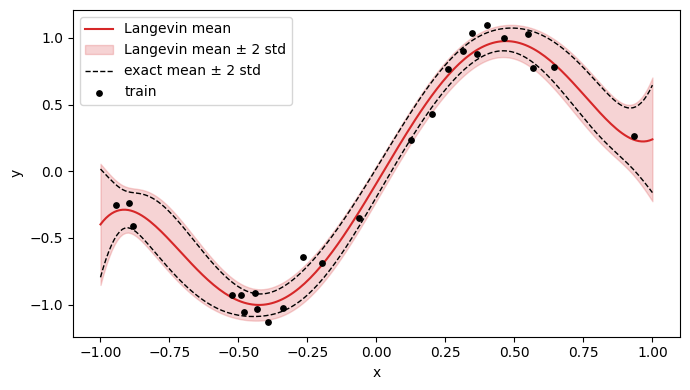

In [8]:
with torch.no_grad():
    X_test = torch.linspace(-1, 1, 201).unsqueeze(-1)
    langevin_samples = surrogate_model(X_test, particles).squeeze(-1)
    exact_samples = surrogate_model(X_test, exact_posterior.sample((2000,))).squeeze(-1)

x_plot = X_test.squeeze(-1)
_, ax = plt.subplots(figsize=(7, 4))
mean, std = langevin_samples.mean(0), langevin_samples.std(0)
ax.plot(x_plot, mean, color="tab:red", label="Langevin mean")
ax.fill_between(x_plot, mean - 2 * std, mean + 2 * std, color="tab:red", alpha=0.2, label="Langevin mean ± 2 std")
mean, std = exact_samples.mean(0), exact_samples.std(0)
ax.plot(x_plot, mean - 2 * std, color="black", ls="--", lw=1, label="exact mean ± 2 std")
ax.plot(x_plot, mean + 2 * std, color="black", ls="--", lw=1)
ax.scatter(X.squeeze(-1), Y.squeeze(-1), color="black", s=15, label="train", zorder=3)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.tight_layout()

## Particle trajectories

Each panel shows 128 particle trajectories for one coefficient, plotted against the pseudo-time $t = k h$. The particles start from $\mathcal{N}(0, \sigma_0^2)$ and are transported by the learned drift toward the posterior. The black line and gray band mark the exact posterior mean $\pm 2$ standard deviations.

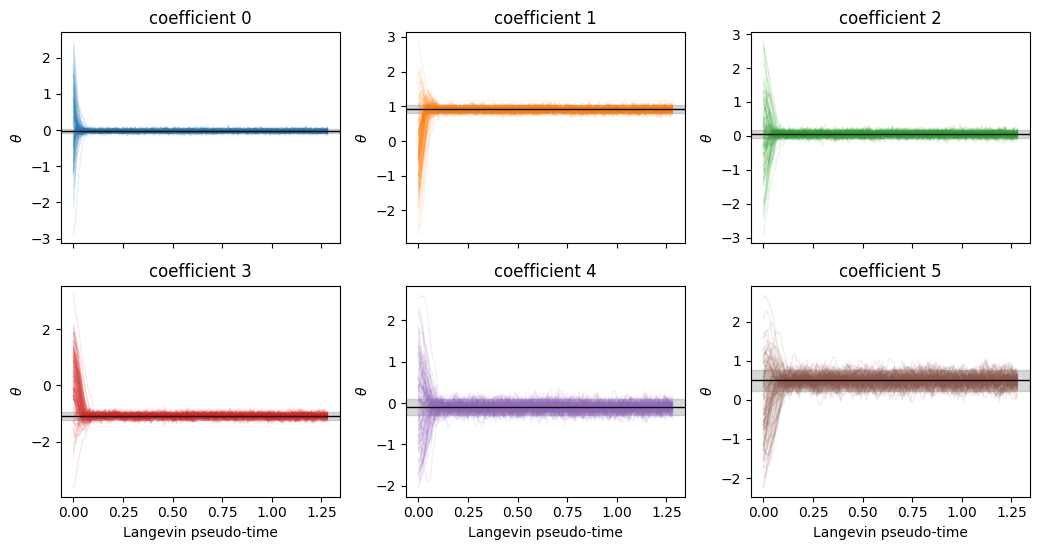

In [9]:
pseudo_time = torch.arange(trajectory.shape[0]) * record_every * group.step_size
num_shown = 128

ncols = 3
nrows = (num_params + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.8 * nrows), sharex=True)
axes = axes.flatten()

for j in range(num_params):
    ax = axes[j]
    ax.plot(pseudo_time, trajectory[:, :num_shown, j], color=f"C{j}", alpha=0.1, linewidth=1.0)
    ax.axhline(post_mean[j], color="black", lw=1)
    ax.axhspan(post_mean[j] - 2 * post_std[j], post_mean[j] + 2 * post_std[j], color="gray", alpha=0.3)
    ax.set_title(f"coefficient {j}")
    ax.set_ylabel(r"$\theta$")
for ax in axes[num_params:]:
    ax.axis("off")
for ax in axes[nrows * ncols - ncols :]:
    ax.set_xlabel("Langevin pseudo-time")

plt.tight_layout()

## Particle distributions at the start and end of the chain

Histograms of all 2000 particles at $t = 0$ and $t = T$, with the exact marginal posterior density overlaid.

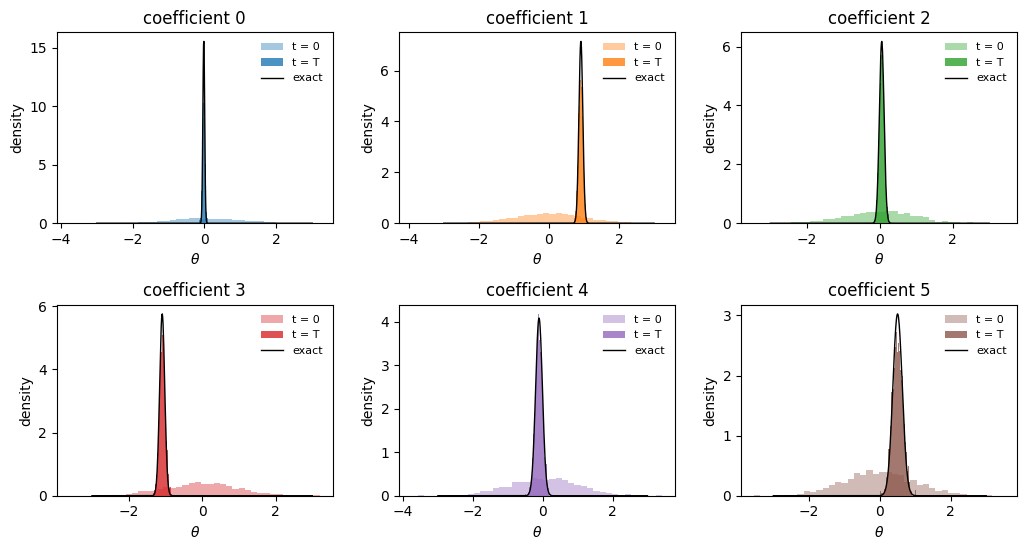

In [10]:
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.8 * nrows))
axes = axes.flatten()

for j in range(num_params):
    ax = axes[j]
    ax.hist(trajectory[0, :, j], bins=40, density=True, alpha=0.4, color=f"C{j}", label="t = 0")
    ax.hist(trajectory[-1, :, j], bins=40, density=True, alpha=0.8, color=f"C{j}", label="t = T")
    lo, hi = post_mean[j] - 5 * post_std[j], post_mean[j] + 5 * post_std[j]
    grid = torch.linspace(min(lo.item(), -3.0), max(hi.item(), 3.0), 600)
    density = torch.distributions.Normal(post_mean[j], post_std[j]).log_prob(grid).exp()
    ax.plot(grid, density, color="black", lw=1, label="exact")
    ax.set_title(f"coefficient {j}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("density")
    ax.legend(frameon=False, loc="upper right", fontsize=8)
for ax in axes[num_params:]:
    ax.axis("off")

plt.tight_layout()